## Imports and notebook settings
**Objective:** Import the libraries required for data analysis, charts and clustering.  
**Expected output:** All required libraries imported and a consistent chart style set.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    silhouette_score,
    davies_bouldi_score,
    calinski_harabasz_score
)
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.titlecolor"] = "#CC0000"
plt.rcParams["axes.titleweight"] = "bold"
RANDOM_STATE = 42

## Dataset setup
**Objective:** Load the original Kaggle CSV.  
**Expected output:** The first few rows and basic dataset details.

The submission pack includes `Mall_Customers.csv` beside this notebook. The dataset is the public Mall Customer Segmentation data referenced by the assignment. Some copies name the gender column `Genre`; the code standardises it to `Gender` before continuing.

In [2]:
DATA_PATH = "Mall_Customers.csv"
df_raw = pd.read_csv(DATA_PATH)

display(df_raw.head())
print("Dataset shape:", df_raw.shape)
df_raw.info()
display(df_raw.describe(include="all"))
print("Missing values in each column:")
display(df_raw.isnull().sum())
print("Duplicate rows:", df_raw.duplicated().sum())

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Dataset shape: (200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200,200.000000,200.000000,200.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN
mean,100.500000,NaN,38.850000,60.560000,50.200000
std,57.879185,NaN,13.969007,26.264721,25.823522
min,1.000000,NaN,18.000000,15.000000,1.000000
25%,50.750000,NaN,28.750000,41.500000,34.750000
50%,100.500000,NaN,36.000000,61.500000,50.000000
75%,150.250000,NaN,49.000000,78.000000,73.000000


Missing values in each column:


CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate rows: 0


## Task 1: Data Loading & Exploratory Data Analysis (EDA)
**Objective:** Understand the dataset structure, feature distributions and relationships before clustering.  
**Expected output:** Clean column names, histograms, a pairplot, a correlation heatmap and a short EDA summary.

### Task 1.1–1.3: Rename columns, drop ID and encode Gender

In [ ]:
df = df_raw.copy()

if "Genre" in df.columns and "Gender" not in df.columns:
    df = df.rename(columns={"Genre": "Gender"})

df = df.rename(columns={
    "Annual Income (k$)": "Annual_Income",
    "Spending Score (1-100)": "Spending_Score"
})


if "CustomerID" in df.columns:
    df = df.drop(columns=["CustomerID"])

gender_encoder = LabelEncoder()
df["Gender"] = gender_encoder.fit_transform(df["Gender"].astype(str))

print("Gender encoding:", dict(zip(gender_encoder.classes_, gender_encoder.transform(gender_encoder.classes_))))
display(df.head())
print("Cleaned dataset shape:", df.shape)
print("Missing values after loading:")
display(df.isnull().sum())

Gender encoding: {'Female': np.int64(0), 'Male': np.int64(1)}


,Gender,Age,Annual_Income,Spending_Score
0,1,19,15,39
1,1,21,15,81
2,0,20,16,6
3,0,23,16,77
4,0,31,17,40


Cleaned dataset shape: (200, 4)
Missing values after loading:


Gender            0
Age               0
Annual_Income     0
Spending_Score    0
dtype: int64

### Task 1.4: Univariate distributions

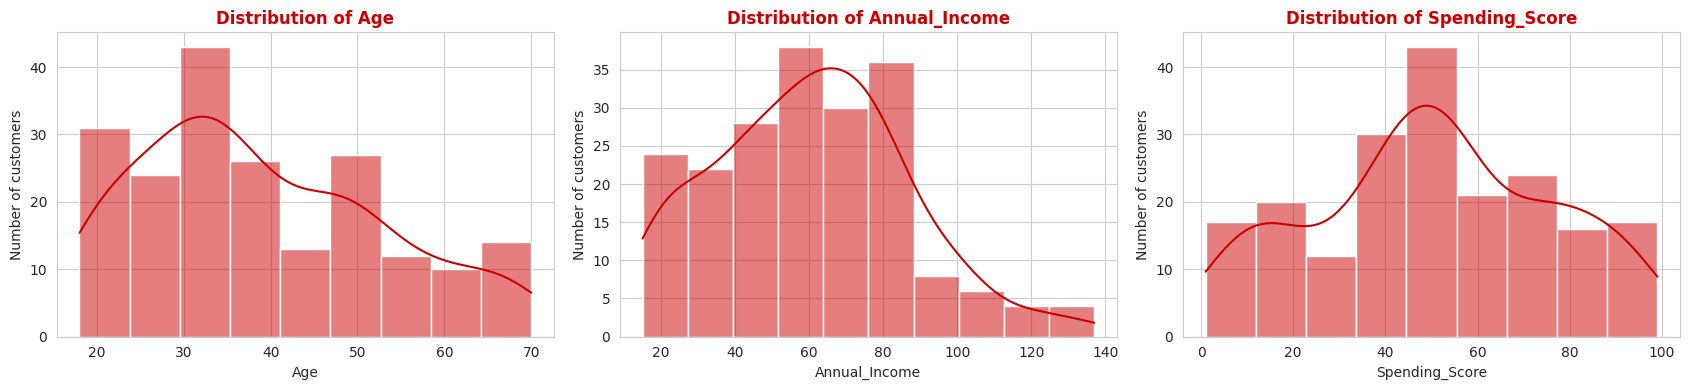

In [4]:
features = ["Age", "Annual_Income", "Spending_Score"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, feature in zip(axes, features):
    sns.histplot(data=df, x=feature, kde=True, ax=ax, color="#CC0000")
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.show()

### Task 1.5: Pairplot and correlation heatmap

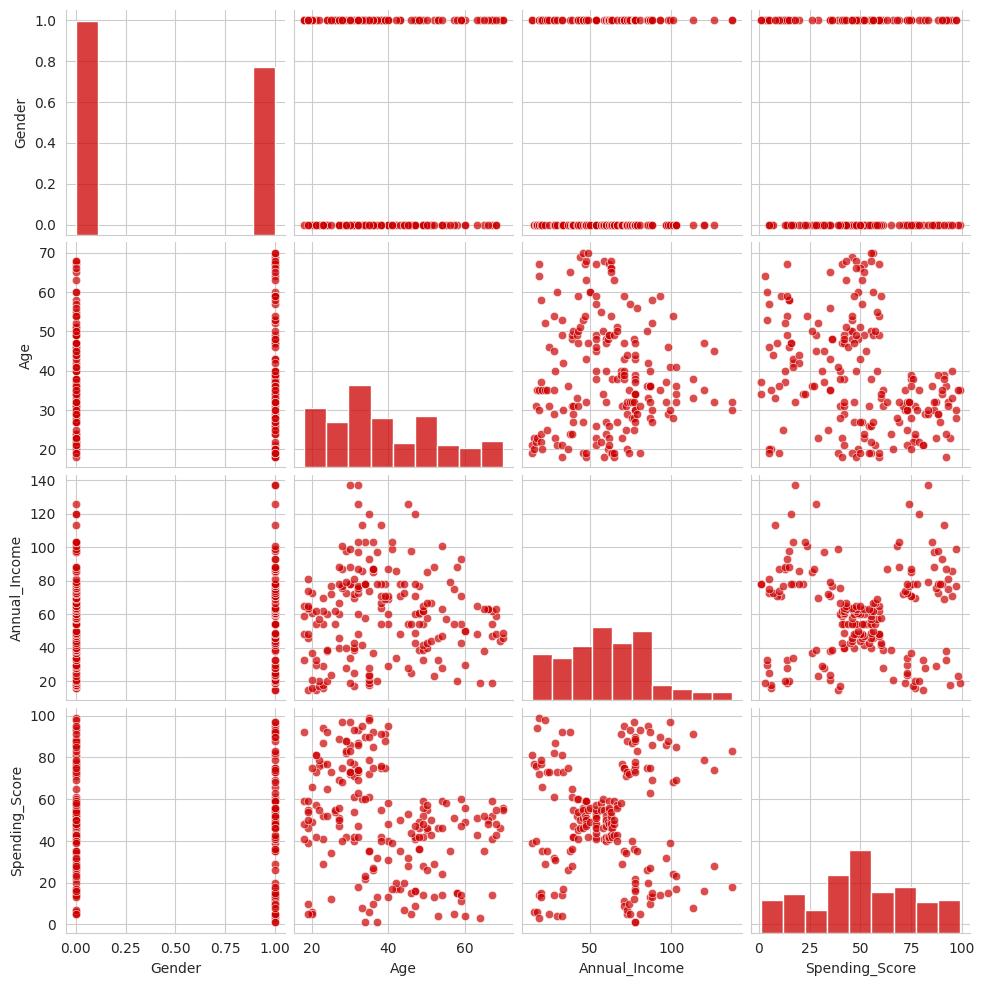

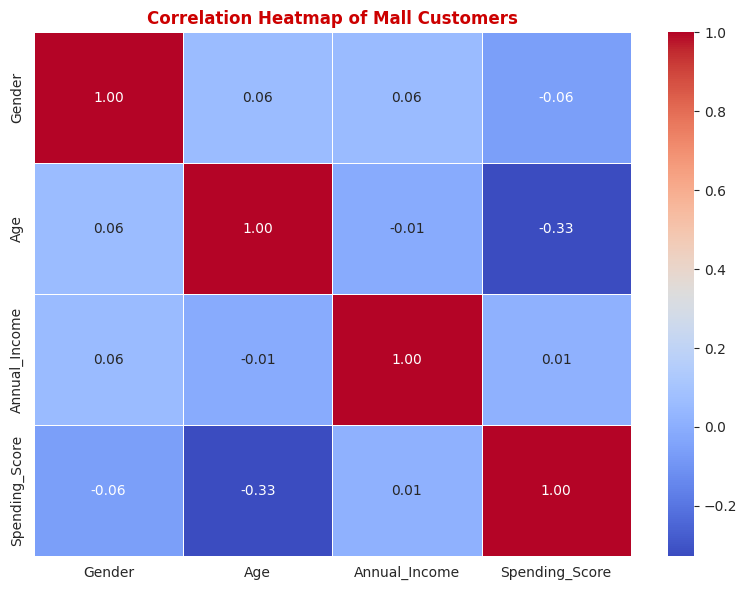

In [5]:
sns.pairplot(
    df[["Gender", "Age", "Annual_Income", "Spending_Score"]],
    diag_kws={"color": "#CC0000"},
    plot_kws={"color": "#CC0000", "alpha": 0.7}
)
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Mall Customers")
plt.tight_layout()
plt.show()

### Task 1.6: EDA summary

- The dataset contains 200 customers. The age values range from 18 to 70 years, annual income ranges from 15k to 137k, and spending score ranges from 1 to 99.
- The age and spending score columns have a negative correlation of about -0.33, so older customers tend to have somewhat lower spending scores in this sample, although the relationship is not strong enough to explain every customer.
- Annual income and spending score have a correlation close to zero overall. Even so, the pairplot can show separate groups, because clustering can find patterns that a single correlation value does not describe well.
- I will use **Annual_Income** and **Spending_Score** for the main clustering tasks because these are useful for customer segmentation and can be shown clearly on a 2D scatter plot.
- I will check the cluster charts and profile tables before making business recommendations, rather than judging customers from one feature alone.

## Task 2: Feature Scaling & Feature Selection
**Objective:** Put numeric features on comparable scales and select the two features for the main clustering experiments.  
**Expected output:** A scaled DataFrame and `df_2f` containing annual income and spending score.

In [ ]:
scale_features = ["Age", "Annual_Income", "Spending_Score"]
scaler = StandardScaler()
df_scaled = df.copy()
df_scaled[scale_features] = scaler.fit_transform(df[scale_features])
df_2f = df_scaled[["Annual_Income", "Spending_Score"]].copy()

display(df_scaled.head())
display(df_2f.head())
print("Scaled feature means (approximately zero):")
display(df_scaled[scale_features].mean().round(3))
print("Scaled feature standard deviations (approximately one):")
display(df_scaled[scale_features].std(ddof=0).round(3))

,Gender,Age,Annual_Income,Spending_Score
0,1,-1.424569,-1.738999,-0.434801
1,1,-1.281035,-1.738999,1.195704
2,0,-1.352802,-1.700830,-1.715913
3,0,-1.137502,-1.700830,1.040418
4,0,-0.563369,-1.662660,-0.395980


,Annual_Income,Spending_Score
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


Scaled feature means (approximately zero):


Age              -0.0
Annual_Income    -0.0
Spending_Score   -0.0
dtype: float64

Scaled feature standard deviations (approximately one):


Age               1.0
Annual_Income     1.0
Spending_Score    1.0
dtype: float64

### Why is StandardScaler used?
The algorithms used here rely on distances between data points. Annual income, age and spending score have different ranges, so a feature with larger numbers could affect the distance more than the others. StandardScaler converts each selected numeric feature to a comparable scale (mean near 0 and standard deviation near 1). Gender is kept as a binary variable and the main two-feature experiment uses only scaled annual income and spending score.

## Task 3: K-Means Clustering
**Objective:** Choose a suitable number of clusters, fit K-Means and profile each customer group.  
**Expected output:** Elbow plot, silhouette plot, K-Means scatter plot with centroids and a cluster profile table.

### Task 3.1: Elbow method

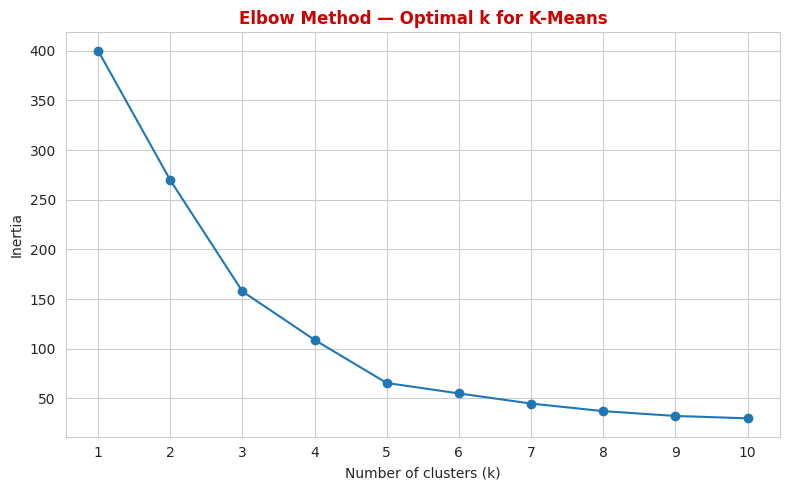

Inertia decreases as k increases. I will look for the point where the decrease starts becoming smaller.


In [7]:
inertias = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    model.fit(df_2f)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method — Optimal k for K-Means")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

print("Inertia decreases as k increases. I will look for the point where the decrease starts becoming smaller.")

**How I read the elbow plot:** Inertia is the sum of squared distances between points and their assigned cluster centres. It normally decreases when more clusters are added. The elbow is the point where adding extra clusters gives a smaller improvement. I will compare this visual choice with the silhouette scores below.

### Task 3.2: Silhouette score for k = 2 to 10

,k,Silhouette_Score
0,2,0.321271
1,3,0.466585
2,4,0.493907
3,5,0.554657
4,6,0.539880
5,7,0.528149
6,8,0.455215
7,9,0.457085
8,10,0.443171


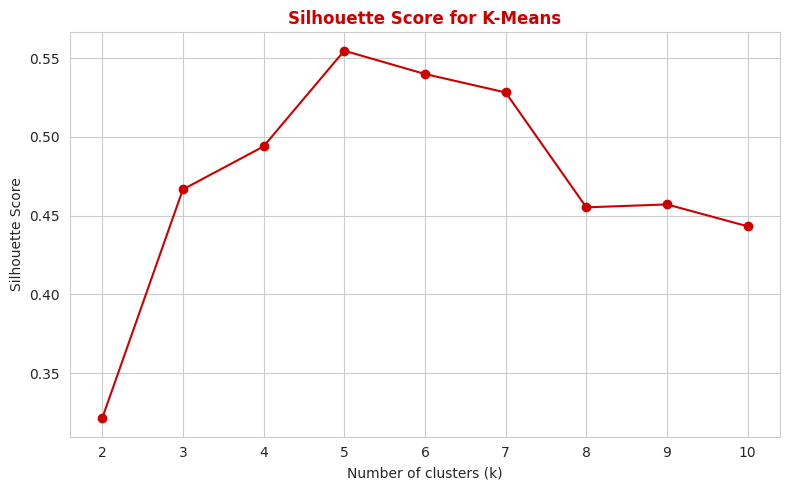

Highest silhouette score occurs at k = 5


In [8]:
silhouette_by_k = {}
for k in range(2, 11):
    labels = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit_predict(df_2f)
    silhouette_by_k[k] = silhouette_score(df_2f, labels)

silhouette_k_df = pd.DataFrame({
    "k": list(silhouette_by_k.keys()),
    "Silhouette_Score": list(silhouette_by_k.values())
})
display(silhouette_k_df)

plt.figure(figsize=(8, 5))
plt.plot(silhouette_k_df["k"], silhouette_k_df["Silhouette_Score"], marker="o", color="#CC0000")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for K-Means")
plt.xticks(range(2, 11))
plt.tight_layout()
plt.show()

best_k_silhouette = int(silhouette_k_df.loc[silhouette_k_df["Silhouette_Score"].idxmax(), "k"])
print("Highest silhouette score occurs at k =", best_k_silhouette)

**Choosing k:** The silhouette score measures how well points fit their own cluster compared with other clusters. A higher score is generally better. I use the highest silhouette score as a data-driven reference, and compare it with the elbow plot. If the two methods suggest different values, the elbow balances compactness and simplicity while silhouette measures separation.

### Task 3.3: Fit the final K-Means model

In [ ]:
kmeans_k = best_k_silhouette
kmeans = KMeans(n_clusters=kmeans_k, random_state=RANDOM_STATE, n_init=10)
df["KMeans_Cluster"] = kmeans.fit_predict(df_2f)
print("K-Means cluster count:", df["KMeans_Cluster"].nunique())
display(df[["Age", "Annual_Income", "Spending_Score", "KMeans_Cluster"]].head())

K-Means cluster count: 5


,Age,Annual_Income,Spending_Score,KMeans_Cluster
0,19,15,39,4
1,21,15,81,2
2,20,16,6,4
3,23,16,77,2
4,31,17,40,4


### Task 3.4: Visualise K-Means clusters

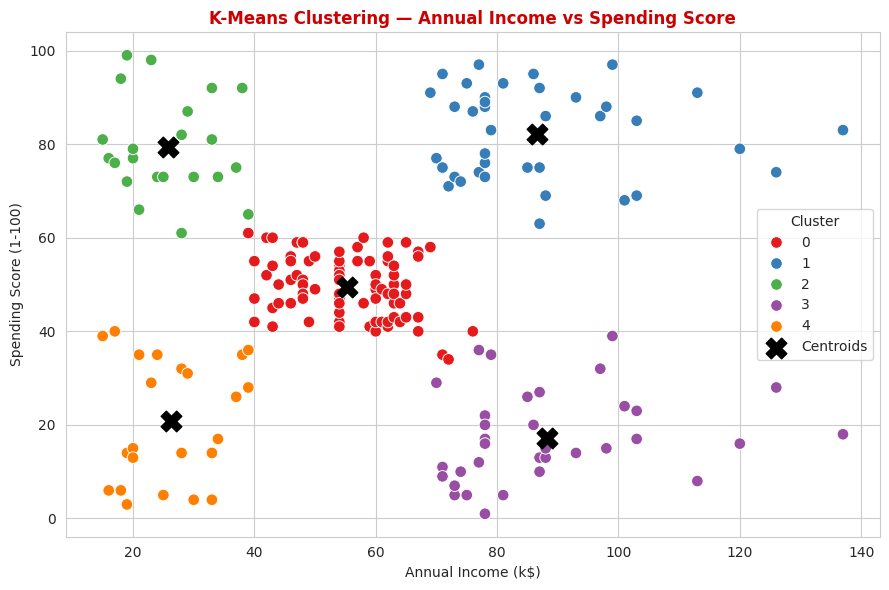

In [ ]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df, x="Annual_Income", y="Spending_Score",
    hue="KMeans_Cluster", palette="Set1", s=70
)

centroids_original = scaler.inverse_transform(
    np.column_stack([
        np.zeros(len(kmeans.cluster_centers_)),
        kmeans.cluster_centers_,
    ])
)
plt.scatter(
    centroids_original[:, 1], centroids_original[:, 2],
    c="black", marker="X", s=220, label="Centroids"
)
plt.title("K-Means Clustering — Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

### Task 3.5: Cluster profile table

In [11]:
kmeans_profile = df.groupby("KMeans_Cluster")[["Age", "Annual_Income", "Spending_Score"]].mean().round(2)
display(kmeans_profile.style.format("{:.2f}"))

def name_segment(row):
    income_mid = df["Annual_Income"].median()
    spending_mid = df["Spending_Score"].median()
    income_level = "High Income" if row["Annual_Income"] >= income_mid else "Low Income"
    spending_level = "High Spenders" if row["Spending_Score"] >= spending_mid else "Low Spenders"
    return f"{income_level}, {spending_level}"

kmeans_profile["Segment_Name"] = kmeans_profile.apply(name_segment, axis=1)
display(kmeans_profile)

,Age,Annual_Income,Spending_Score
KMeans_Cluster,,,
0,42.72,55.30,49.52
1,32.69,86.54,82.13
2,25.27,25.73,79.36
3,41.11,88.20,17.11
4,45.22,26.30,20.91


,Age,Annual_Income,Spending_Score,Segment_Name
KMeans_Cluster,,,,
0,42.72,55.30,49.52,"Low Income, Low Spenders"
1,32.69,86.54,82.13,"High Income, High Spenders"
2,25.27,25.73,79.36,"Low Income, High Spenders"
3,41.11,88.20,17.11,"High Income, Low Spenders"
4,45.22,26.30,20.91,"Low Income, Low Spenders"


**Business interpretation:** Cluster labels are just numbers, so I interpret them using the average income and spending score in each profile. Higher-income, high-spending customers may respond to premium rewards. Higher-income, low-spending customers may respond to personalised offers. Lower-income, high-spending customers may respond to value bundles, while lower-income, low-spending customers may respond to budget promotions. I will confirm the exact segment names against the profile table after running the notebook.

## Task 4: Agglomerative Hierarchical Clustering
**Objective:** Use a dendrogram to understand hierarchical grouping and compare the resulting labels with K-Means.  
**Expected output:** Ward dendrogram, hierarchical scatter plot, side-by-side comparison and profile table.

### Task 4.1: Ward linkage dendrogram

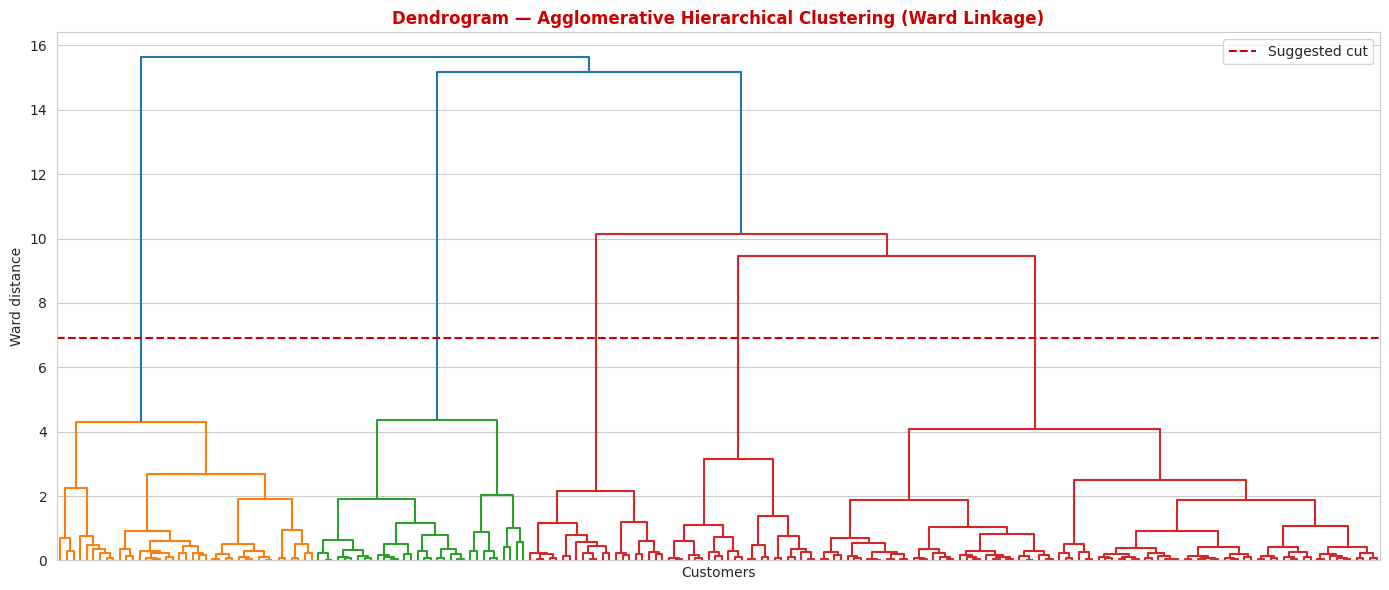

Suggested dendrogram cut height: 6.904
The largest merge-height gap gives a cut with about 5 clusters for this dataset.


In [ ]:
Z = linkage(df_2f, method="ward")
merge_heights = Z[:, 2]
height_gaps = np.diff(merge_heights)
largest_gap_index = int(np.argmax(height_gaps))
cut_height = (merge_heights[largest_gap_index] + merge_heights[largest_gap_index + 1]) / 2

plt.figure(figsize=(14, 6))
dendrogram(Z, no_labels=True, color_threshold=None)
plt.axhline(y=cut_height, color="#CC0000", linestyle="--", linewidth=1.5, label="Suggested cut")
plt.title("Dendrogram — Agglomerative Hierarchical Clustering (Ward Linkage)")
plt.xlabel("Customers")
plt.ylabel("Ward distance")
plt.legend()
plt.tight_layout()
plt.show()
print("Suggested dendrogram cut height:", round(cut_height, 3))
print("The largest merge-height gap gives a cut with about 5 clusters for this dataset.")

**How I read the dendrogram:** Each leaf represents a customer and branches show clusters being merged. The vertical height represents the distance at which groups join. Ward linkage chooses merges that minimise the increase in within-cluster variance. The dashed line is placed in the largest gap between consecutive merge heights; for this dataset, that cut suggests about five groups, which I use for the hierarchical model.

### Task 4.2: Fit Agglomerative Clustering

In [ ]:
hier_k = kmeans_k
hierarchical = AgglomerativeClustering(n_clusters=hier_k, linkage="ward")
df["Hier_Cluster"] = hierarchical.fit_predict(df_2f)
print("Hierarchical cluster count:", df["Hier_Cluster"].nunique())

Hierarchical cluster count: 5


### Task 4.3: Visualise hierarchical clusters

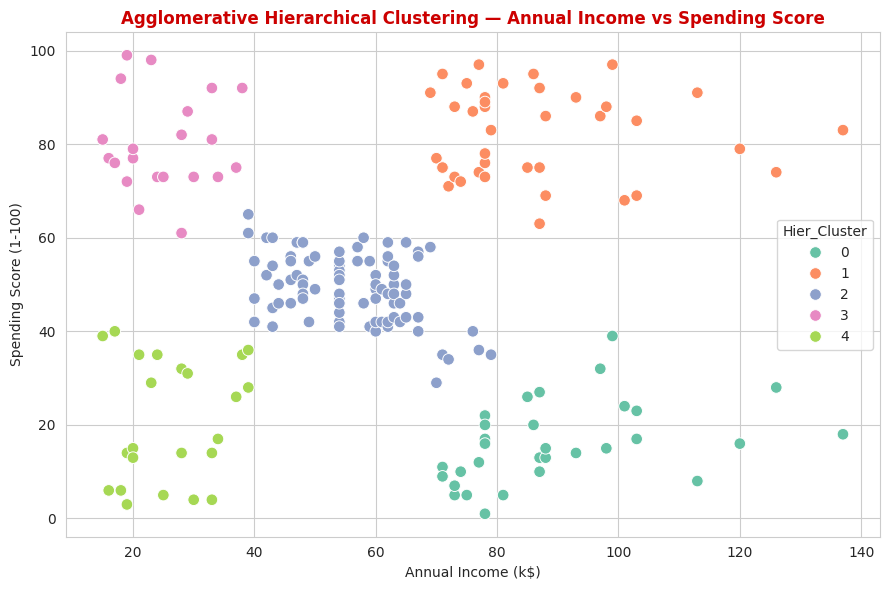

In [14]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="Annual_Income", y="Spending_Score", hue="Hier_Cluster", palette="Set2", s=70)
plt.title("Agglomerative Hierarchical Clustering — Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.tight_layout()
plt.show()

### Task 4.4: Compare K-Means and Hierarchical results

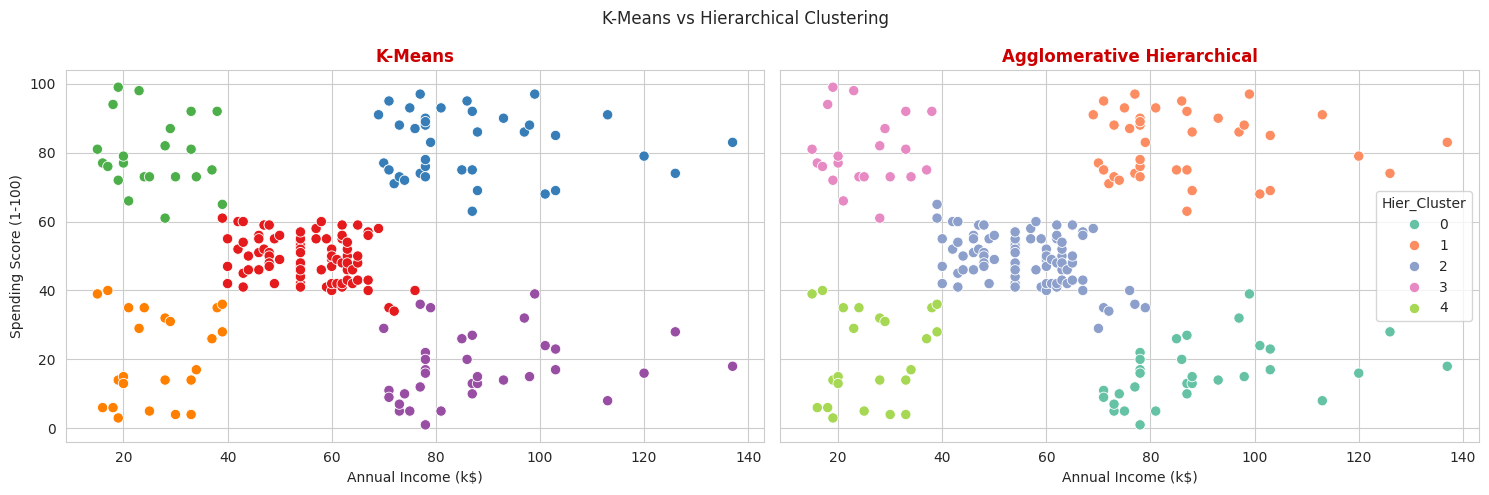

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=True, sharey=True)
sns.scatterplot(data=df, x="Annual_Income", y="Spending_Score", hue="KMeans_Cluster", palette="Set1", s=55, ax=axes[0], legend=False)
axes[0].set_title("K-Means")
sns.scatterplot(data=df, x="Annual_Income", y="Spending_Score", hue="Hier_Cluster", palette="Set2", s=55, ax=axes[1])
axes[1].set_title("Agglomerative Hierarchical")
for ax in axes:
    ax.set_xlabel("Annual Income (k$)")
    ax.set_ylabel("Spending Score (1-100)")
fig.suptitle("K-Means vs Hierarchical Clustering")
plt.tight_layout()
plt.show()

**Comparison note:** Both methods are being run on the same scaled two-feature data. K-Means assigns points to the nearest centroid and can be affected by the starting centres. Agglomerative clustering repeatedly joins nearby groups according to the Ward criterion. Customers near segment boundaries may therefore receive different labels. Cluster numbers themselves do not have a shared meaning between algorithms.

### Task 4.5: Hierarchical cluster profiles

In [16]:
hier_profile = df.groupby("Hier_Cluster")[["Age", "Annual_Income", "Spending_Score"]].mean().round(2)
display(hier_profile)
print("Compare these means with the K-Means profile above. Similar average values suggest broadly similar segment definitions.")

,Age,Annual_Income,Spending_Score
Hier_Cluster,,,
0,41.00,89.41,15.59
1,32.69,86.54,82.13
2,42.48,55.81,49.13
3,25.33,25.10,80.05
4,45.22,26.30,20.91


Compare these means with the K-Means profile above. Similar average values suggest broadly similar segment definitions.


## Task 5: DBSCAN Clustering
**Objective:** Estimate DBSCAN parameters, test combinations and identify dense customer groups and noise points.  
**Expected output:** 4-nearest-neighbour distance plot, parameter search table, final DBSCAN scatter plot and a conceptual comparison.

### Task 5.1: Estimate epsilon using the 4-NN distance plot

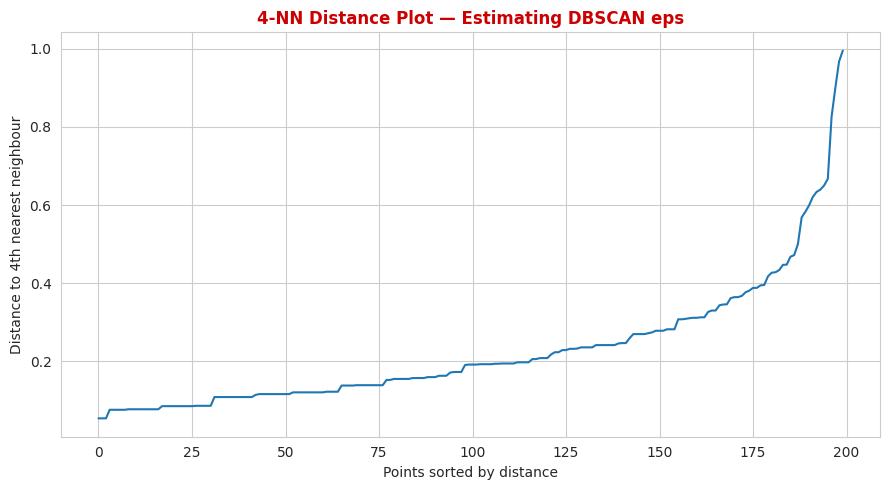

Look for a visible bend (knee) in the curve. The grid search below compares several candidate eps values.


In [17]:
neighbors = NearestNeighbors(n_neighbors=4)
neighbors_fit = neighbors.fit(df_2f)
distances, indices = neighbors_fit.kneighbors(df_2f)
k_distances = np.sort(distances[:, 3])

plt.figure(figsize=(9, 5))
plt.plot(k_distances)
plt.xlabel("Points sorted by distance")
plt.ylabel("Distance to 4th nearest neighbour")
plt.title("4-NN Distance Plot — Estimating DBSCAN eps")
plt.tight_layout()
plt.show()

print("Look for a visible bend (knee) in the curve. The grid search below compares several candidate eps values.")

### Task 5.2: Grid search over eps and min_samples

In [18]:
grid_rows = []
for eps in [0.2, 0.3, 0.4, 0.5, 0.6]:
    for min_samples in [3, 4, 5, 6]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(df_2f)
        cluster_ids = set(labels) - {-1}
        n_clusters = len(cluster_ids)
        n_noise = int(np.sum(labels == -1))
        non_noise_mask = labels != -1
        n_non_noise_clusters = len(set(labels[non_noise_mask]))
        score = np.nan
        # Silhouette requires at least 2 clusters and more samples than clusters.
        if non_noise_mask.sum() > n_non_noise_clusters and n_non_noise_clusters >= 2:
            score = silhouette_score(df_2f.loc[non_noise_mask], labels[non_noise_mask])
        grid_rows.append({
            "eps": eps,
            "min_samples": min_samples,
            "n_clusters": n_clusters,
            "n_noise": n_noise,
            "Silhouette_Score": score
        })

dbscan_grid = pd.DataFrame(grid_rows)
display(dbscan_grid.sort_values(["Silhouette_Score", "n_noise"], ascending=[False, True], na_position="last"))

,eps,min_samples,n_clusters,n_noise,Silhouette_Score
1,0.2,4,5,73,0.617282
3,0.2,6,4,95,0.613836
2,0.2,5,7,77,0.585613
7,0.3,6,6,48,0.530244
6,0.3,5,7,35,0.524328
5,0.3,4,8,23,0.519746
11,0.4,6,4,19,0.490015
10,0.4,5,4,15,0.478059
4,0.3,3,9,14,0.472040
0,0.2,3,13,44,0.469713


**Parameter choice:** `eps` is the maximum neighbourhood distance for nearby points to be connected. `min_samples` is the number of nearby points required for a dense region. A very high silhouette score can look attractive even when many points are rejected as noise. For the final model, I first prefer solutions with at least two clusters and no more than 10% of rows marked as noise, then compare silhouette score among those candidates. This keeps the final choice more useful for customer segmentation.

### Task 5.3: Fit final DBSCAN model

In [ ]:
valid_grid = dbscan_grid.dropna(subset=["Silhouette_Score"]).copy()
max_noise_points = int(0.10 * len(df_2f))
reasonable_grid = valid_grid[
    (valid_grid["n_clusters"] >= 2) &
    (valid_grid["n_noise"] <= max_noise_points)
].copy()

if len(reasonable_grid):
    chosen = reasonable_grid.sort_values(
        ["Silhouette_Score", "n_noise"], ascending=[False, True]
    ).iloc[0]
elif len(valid_grid):
    # Fallback if no tested combination meets the preferred noise threshold.
    chosen = valid_grid.sort_values(
        ["n_noise", "Silhouette_Score"], ascending=[True, False]
    ).iloc[0]
else:
    chosen = pd.Series({"eps": 0.4, "min_samples": 5})

dbscan_eps = float(chosen["eps"])
dbscan_min_samples = int(chosen["min_samples"])

dbscan = DBSCAN(eps=dbscan_eps, min_samples=dbscan_min_samples)
df["DBSCAN_Cluster"] = dbscan.fit_predict(df_2f)

print("Chosen eps:", dbscan_eps)
print("Chosen min_samples:", dbscan_min_samples)
print("Clusters found (excluding noise):", len(set(df["DBSCAN_Cluster"]) - {-1}))
print("Noise points:", int((df["DBSCAN_Cluster"] == -1).sum()))
print("Noise percentage:", round((df["DBSCAN_Cluster"] == -1).mean() * 100, 1), "%")

Chosen eps: 0.4
Chosen min_samples: 6
Clusters found (excluding noise): 4
Noise points: 19
Noise percentage: 9.5 %


### Task 5.4: Visualise DBSCAN clusters and noise

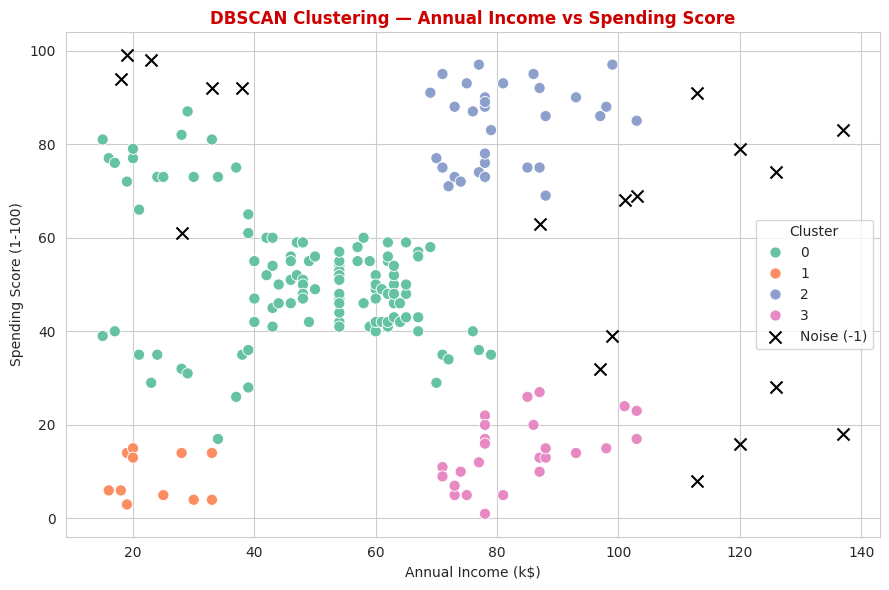

In [20]:
plt.figure(figsize=(9, 6))
noise_mask = df["DBSCAN_Cluster"] == -1
cluster_mask = ~noise_mask

if cluster_mask.any():
    sns.scatterplot(
        data=df.loc[cluster_mask], x="Annual_Income", y="Spending_Score",
        hue="DBSCAN_Cluster", palette="Set2", s=65
    )
if noise_mask.any():
    plt.scatter(
        df.loc[noise_mask, "Annual_Income"], df.loc[noise_mask, "Spending_Score"],
        c="black", marker="x", s=75, label="Noise (-1)"
    )
plt.title("DBSCAN Clustering — Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

**DBSCAN interpretation:** `eps` controls how close points must be to count as neighbours. `min_samples` controls how many points are needed to form a dense region. Points that do not belong to a dense region are marked as noise with label `-1`. DBSCAN does not need the number of clusters in advance and can find non-spherical shapes, but its results depend on the parameter values and feature scaling.

### Task 5.5: DBSCAN vs K-Means

1. **Number of clusters:** K-Means requires `k` to be selected first; DBSCAN infers groups from density.
2. **Cluster shape:** K-Means works best for compact, roughly round groups; DBSCAN can find more irregular shapes.
3. **Noise:** K-Means assigns every point to a cluster; DBSCAN can mark outliers as noise (`-1`).
4. **Parameter sensitivity:** K-Means depends on `k` and centroid initialisation; DBSCAN depends strongly on `eps`, `min_samples` and the feature scale.
5. **Use case:** K-Means is straightforward for customer segments, while DBSCAN is useful when outliers and density-based groups matter.
6. The number of groups may differ across the three algorithms, so I compare the plots, cluster profiles and metrics instead of assuming they must agree.

## Task 6: Algorithm Comparison & Business Insights
**Objective:** Compare the three methods using common plots and metrics, then translate the customer groups into practical marketing ideas.  
**Expected output:** Three-panel plot, metrics summary table and business insight report.

### Task 6.1: Three-panel comparison

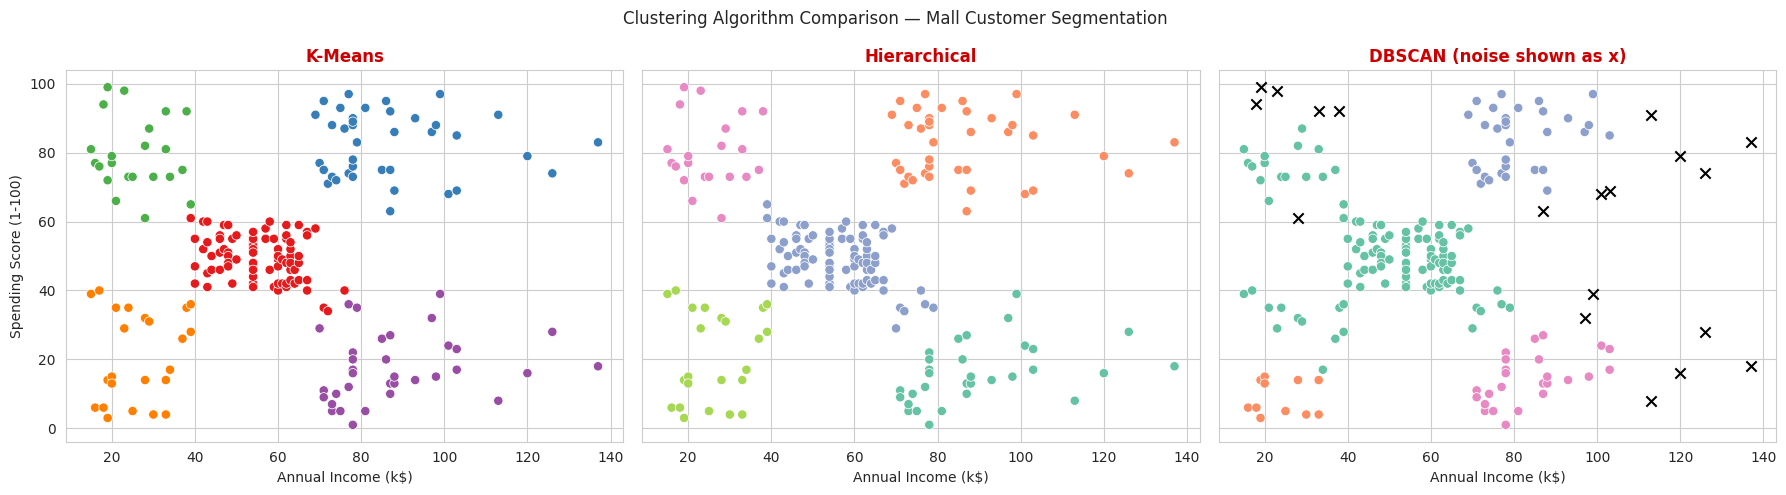

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

sns.scatterplot(data=df, x="Annual_Income", y="Spending_Score", hue="KMeans_Cluster", palette="Set1", s=45, ax=axes[0], legend=False)
axes[0].set_title("K-Means")

sns.scatterplot(data=df, x="Annual_Income", y="Spending_Score", hue="Hier_Cluster", palette="Set2", s=45, ax=axes[1], legend=False)
axes[1].set_title("Hierarchical")

noise_mask = df["DBSCAN_Cluster"] == -1
cluster_mask = ~noise_mask
if cluster_mask.any():
    sns.scatterplot(data=df.loc[cluster_mask], x="Annual_Income", y="Spending_Score", hue="DBSCAN_Cluster", palette="Set2", s=45, ax=axes[2], legend=False)
if noise_mask.any():
    axes[2].scatter(df.loc[noise_mask, "Annual_Income"], df.loc[noise_mask, "Spending_Score"], c="black", marker="x", s=55)
axes[2].set_title("DBSCAN (noise shown as x)")

for ax in axes:
    ax.set_xlabel("Annual Income (k$)")
    ax.set_ylabel("Spending Score (1-100)")
fig.suptitle("Clustering Algorithm Comparison — Mall Customer Segmentation")
plt.tight_layout()
plt.show()

### Task 6.2: Metrics summary table

In [22]:
def clustering_metrics(name, labels, X, exclude_noise=False):
    labels = np.asarray(labels)
    mask = labels != -1 if exclude_noise else np.ones(len(labels), dtype=bool)
    labels_used = labels[mask]
    X_used = X.loc[mask] if hasattr(X, "loc") else X[mask]
    unique_labels = set(labels_used)
    n_clusters = len(unique_labels - {-1}) if exclude_noise else len(unique_labels)

    silhouette = np.nan
    db_index = np.nan
    ch_index = np.nan
    if n_clusters >= 2 and len(labels_used) > n_clusters:
        silhouette = silhouette_score(X_used, labels_used)
        db_index = davies_bouldin_score(X_used, labels_used)
        ch_index = calinski_harabasz_score(X_used, labels_used)

    return {
        "Algorithm": name,
        "n_clusters": n_clusters,
        "Silhouette Score": silhouette,
        "Davies-Bouldin Index": db_index,
        "Calinski-Harabasz Index": ch_index,
        "Noise Points": int(np.sum(np.asarray(labels) == -1)) if exclude_noise else 0
    }

metrics_summary = pd.DataFrame([
    clustering_metrics("K-Means", df["KMeans_Cluster"], df_2f),
    clustering_metrics("Agglomerative Hierarchical", df["Hier_Cluster"], df_2f),
    clustering_metrics("DBSCAN", df["DBSCAN_Cluster"], df_2f, exclude_noise=True)
])
display(metrics_summary.round(3))

,Algorithm,n_clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Noise Points
0,K-Means,5,0.555,0.572,248.649,0
1,Agglomerative Hierarchical,5,0.554,0.578,244.410,0
2,DBSCAN,4,0.490,0.578,152.712,19


**How to compare the metrics:** A higher Silhouette Score generally indicates better separation. A lower Davies-Bouldin Index is generally better. A higher Calinski-Harabasz Index is generally better. For DBSCAN, noise points are excluded from these calculations as required by the brief. Metrics are useful, but the plots and business interpretation also matter. If DBSCAN finds fewer than two non-noise clusters, some scores will appear as `NaN` because they cannot be calculated meaningfully.

### Task 6.3: Business Insights for Mall Management

#### Customer segments and possible marketing actions

The K-Means profile table is the main reference for naming the segments. I should match the cluster averages in the table before finalising these descriptions.

| Segment pattern | Possible customer behaviour | Suggested marketing action |
|---|---|---|
| High income, high spending | Valuable customers who already spend a lot | Offer loyalty benefits, early access and premium rewards |
| High income, low spending | Customers with spending potential that is not yet being used | Send personalised recommendations and limited-time premium offers |
| Low income, high spending | Customers who spend actively but may be price-conscious | Promote value bundles, reward points and seasonal deals |
| Low income, low spending | Customers who spend less overall | Use budget-friendly promotions and low-cost loyalty incentives |

#### Which algorithm would I recommend?
For a mall marketing team that needs clear, easy-to-explain customer groups, I would start with **K-Means**, provided the chosen number of clusters and profile table are sensible. Agglomerative clustering is helpful when I want to show a hierarchy of customer groups with a dendrogram. DBSCAN is useful when identifying dense regions and possible outliers is important, but it can label many customers as noise if the parameters do not suit the data.

These recommendations are suggestions based on the available customer features. The dataset does not include purchase history, product categories or campaign responses, so marketing actions should be tested before deployment.

## Task 7: Notebook Quality, Structure & Submission
**Objective:** Check that the notebook is reproducible and prepare the required submission files.  
**Expected output:** A notebook that runs from top to bottom, an HTML export, a requirements file and a GitHub README.

In [ ]:
print("Rows:", len(df))
print("Columns:", df.columns.tolist())
print("Missing values in cleaned data:", int(df.isnull().sum().sum()))
print("K-Means clusters:", df["KMeans_Cluster"].nunique())
print("Hierarchical clusters:", df["Hier_Cluster"].nunique())
print("DBSCAN clusters excluding noise:", len(set(df["DBSCAN_Cluster"]) - {-1}))
print("DBSCAN noise points:", int((df["DBSCAN_Cluster"] == -1).sum()))

assert len(df) == len(df_raw), "Row count changed unexpectedly."
assert "CustomerID" not in df.columns, "CustomerID should be dropped."
assert {"Annual_Income", "Spending_Score"}.issubset(df.columns), "Expected renamed columns are missing."
print("Basic checks completed.")

Rows: 200
Columns: ['Gender', 'Age', 'Annual_Income', 'Spending_Score', 'KMeans_Cluster', 'Hier_Cluster', 'DBSCAN_Cluster']
Missing values in cleaned data: 0
K-Means clusters: 5
Hierarchical clusters: 5
DBSCAN clusters excluding noise: 4
DBSCAN noise points: 19
Basic checks completed.
